In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [2]:
col_names = [f'f{i}' for i in range(1, 58)] + ['label']
df = pd.read_csv('spambase.data', header=None, names=col_names)

print(f'Shape: {df.shape}')
print(f'\nClass distribution:')
print(df['label'].value_counts().rename({0: 'Ham', 1: 'Spam'}))
df.head(3)


Shape: (4601, 58)

Class distribution:
Ham     2788
Spam    1813
Name: label, dtype: int64


,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,...,f49,f50,f51,f52,f53,f54,f55,f56,f57,label
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1


In [3]:
def to_libsvm(X, y, filepath):
    with open(filepath, 'w') as f:
        for label, row in zip(y, X):
            features = ' '.join(f'{i+1}:{v}' for i, v in enumerate(row) if v != 0)
            f.write(f'{int(label)} {features}\n')

X = df.drop('label', axis=1).values
y = df['label'].values

to_libsvm(X, y, 'spambase.libsvm')
print("Saved. First line preview:")
with open('spambase.libsvm') as f:
    print(f.readline()[:120])


Saved. First line preview:
1 2:0.64 3:0.64 5:0.32 12:0.64 16:0.32 18:1.29 19:1.93 21:0.96 52:0.778 55:3.756 56:61.0 57:278.0



In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

C_values = [0.1, 1, 10, 100]
train_accs, test_accs = [], []

for C in C_values:
    svm = SVC(kernel='rbf', C=C, random_state=42)
    svm.fit(X_train_sc, y_train)
    train_accs.append(accuracy_score(y_train, svm.predict(X_train_sc)))
    test_accs.append(accuracy_score(y_test,  svm.predict(X_test_sc)))
    print(f'C={C:<5} | Train: {train_accs[-1]:.4f} | Test: {test_accs[-1]:.4f}')


C=0.1   | Train: 0.9137 | Test: 0.9088
C=1     | Train: 0.9500 | Test: 0.9276
C=10    | Train: 0.9683 | Test: 0.9247
C=100   | Train: 0.9851 | Test: 0.9276


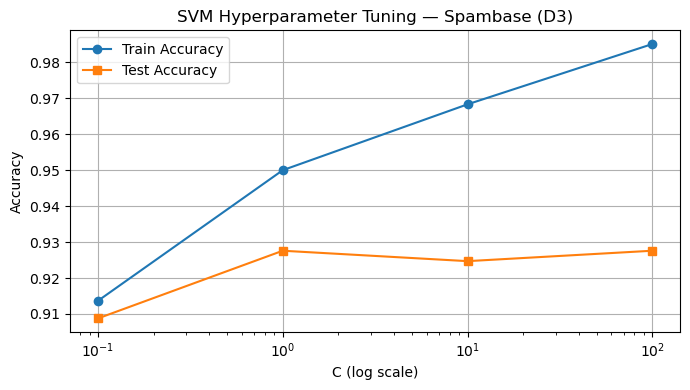

Best C: 1
              precision    recall  f1-score   support

         Ham       0.93      0.95      0.94       837
        Spam       0.93      0.89      0.91       544

    accuracy                           0.93      1381
   macro avg       0.93      0.92      0.92      1381
weighted avg       0.93      0.93      0.93      1381



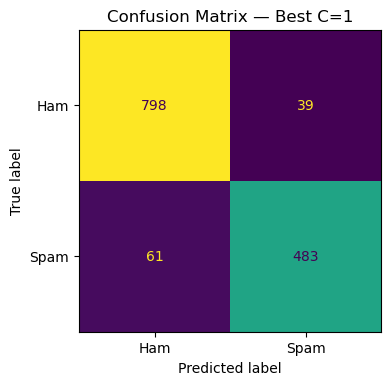

In [5]:
plt.figure(figsize=(7, 4))
plt.semilogx(C_values, train_accs, 'o-', label='Train Accuracy')
plt.semilogx(C_values, test_accs,  's-', label='Test Accuracy')
plt.xlabel('C (log scale)')
plt.ylabel('Accuracy')
plt.title('SVM Hyperparameter Tuning — Spambase (D3)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('fig_partA_C_tuning.png', dpi=150, bbox_inches='tight')
plt.show()

best_C = C_values[np.argmax(test_accs)]
print(f'Best C: {best_C}')

best_svm = SVC(kernel='rbf', C=best_C, random_state=42)
best_svm.fit(X_train_sc, y_train)
y_pred = best_svm.predict(X_test_sc)

print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['Ham', 'Spam'])
fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax, colorbar=False)
plt.title(f'Confusion Matrix — Best C={best_C}')
plt.tight_layout()
plt.savefig('fig_partA_confusion.png', dpi=150, bbox_inches='tight')
plt.show()


In [6]:
sms_df = pd.read_csv('SMSSpamCollection', sep='\t', header=None, names=['label', 'text'])
sms_df['label_num'] = (sms_df['label'] == 'spam').astype(int)

print(f'Shape: {sms_df.shape}')
print(f'\nClass distribution:')
print(sms_df['label'].value_counts())
sms_df.head(4)


Shape: (5572, 3)

Class distribution:
ham     4825
spam     747
Name: label, dtype: int64


,label,text,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0


In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
C_values = [0.1, 1, 10, 100]

print("=== Linear Kernel ===")
results_linear = []
for C in C_values:
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', max_features=5000)),
        ('svm',   SVC(kernel='linear', C=C, random_state=42))
    ])
    scores = cross_val_score(pipe, sms_df['text'], sms_df['label_num'], cv=cv, scoring='accuracy')
    results_linear.append({'C': C, 'mean': scores.mean(), 'std': scores.std()})
    print(f'C={C:<5} | Accuracy: {scores.mean():.4f} ± {scores.std():.4f}')

print("\n=== RBF Kernel ===")
results_rbf = []
for C in C_values:
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', max_features=5000)),
        ('svm',   SVC(kernel='rbf', C=C, random_state=42))
    ])
    scores = cross_val_score(pipe, sms_df['text'], sms_df['label_num'], cv=cv, scoring='accuracy')
    results_rbf.append({'C': C, 'mean': scores.mean(), 'std': scores.std()})
    print(f'C={C:<5} | Accuracy: {scores.mean():.4f} ± {scores.std():.4f}')


=== Linear Kernel ===
C=0.1   | Accuracy: 0.9368 ± 0.0024
C=1     | Accuracy: 0.9833 ± 0.0028
C=10    | Accuracy: 0.9840 ± 0.0015
C=100   | Accuracy: 0.9831 ± 0.0035

=== RBF Kernel ===
C=0.1   | Accuracy: 0.8695 ± 0.0019
C=1     | Accuracy: 0.9808 ± 0.0026
C=10    | Accuracy: 0.9824 ± 0.0031
C=100   | Accuracy: 0.9824 ± 0.0031


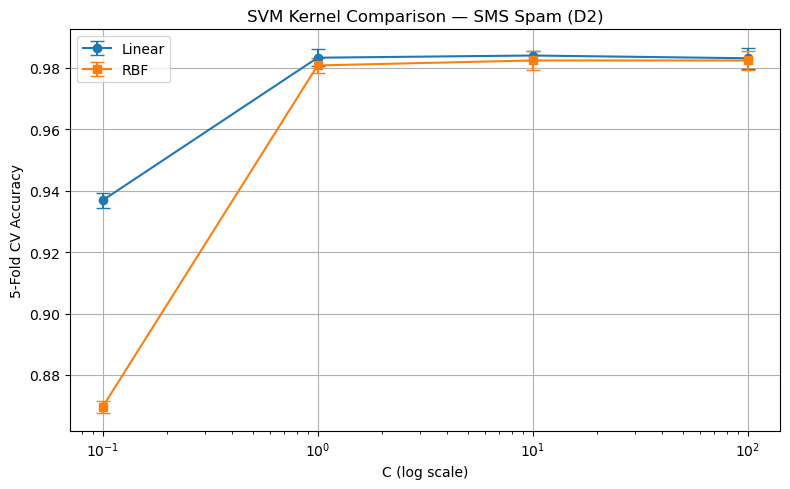

Best linear C: 10.0
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       966
        Spam       0.95      0.87      0.91       149

    accuracy                           0.98      1115
   macro avg       0.96      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



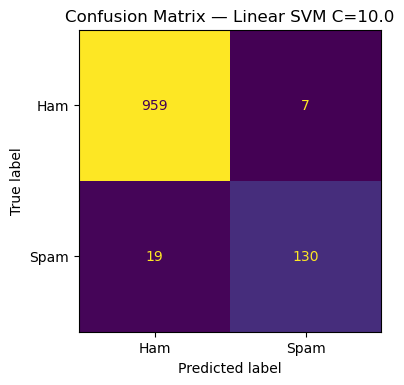

In [8]:
results_linear_df = pd.DataFrame(results_linear)
results_rbf_df    = pd.DataFrame(results_rbf)

plt.figure(figsize=(8, 5))
plt.errorbar(C_values, results_linear_df['mean'], yerr=results_linear_df['std'],
             fmt='o-', capsize=5, label='Linear')
plt.errorbar(C_values, results_rbf_df['mean'],    yerr=results_rbf_df['std'],
             fmt='s-', capsize=5, label='RBF')
plt.xscale('log')
plt.xlabel('C (log scale)')
plt.ylabel('5-Fold CV Accuracy')
plt.title('SVM Kernel Comparison — SMS Spam (D2)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('fig_partB_CV.png', dpi=150, bbox_inches='tight')
plt.show()

best_C_linear = results_linear_df.loc[results_linear_df['mean'].idxmax(), 'C']
print(f'Best linear C: {best_C_linear}')

pipe_best = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=5000)),
    ('svm',   SVC(kernel='linear', C=best_C_linear, random_state=42))
])

X_tr, X_te, y_tr, y_te = train_test_split(
    sms_df['text'], sms_df['label_num'], test_size=0.2, random_state=42, stratify=sms_df['label_num']
)
pipe_best.fit(X_tr, y_tr)
y_te_pred = pipe_best.predict(X_te)

print(classification_report(y_te, y_te_pred, target_names=['Ham', 'Spam']))

cm = confusion_matrix(y_te, y_te_pred)
fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay(cm, display_labels=['Ham', 'Spam']).plot(ax=ax, colorbar=False)
plt.title(f'Confusion Matrix — Linear SVM C={best_C_linear}')
plt.tight_layout()
plt.savefig('fig_partB_confusion.png', dpi=150, bbox_inches='tight')
plt.show()


In [9]:
C_values_lr = [0.1, 1, 10, 100]
results_lr = []

print("=== Logistic Regression ===")
for C in C_values_lr:
    pipe_lr = Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', max_features=5000)),
        ('lr',    LogisticRegression(C=C, max_iter=1000, random_state=42))
    ])
    scores = cross_val_score(pipe_lr, sms_df['text'], sms_df['label_num'], cv=cv, scoring='accuracy')
    results_lr.append({'C': C, 'mean': scores.mean(), 'std': scores.std()})
    print(f'C={C:<5} | Accuracy: {scores.mean():.4f} ± {scores.std():.4f}')

results_lr_df = pd.DataFrame(results_lr)


=== Logistic Regression ===
C=0.1   | Accuracy: 0.8665 ± 0.0006
C=1     | Accuracy: 0.9661 ± 0.0024
C=10    | Accuracy: 0.9813 ± 0.0034
C=100   | Accuracy: 0.9838 ± 0.0030


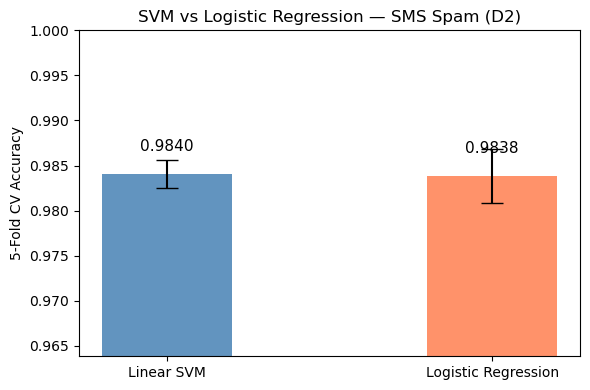


Best SVM  — C=10.0: 0.9840 ± 0.0015
Best LR   — C=100.0:  0.9838 ± 0.0030


In [11]:
best_svm_row = results_linear_df.loc[results_linear_df['mean'].idxmax()]
best_lr_row  = results_lr_df.loc[results_lr_df['mean'].idxmax()]

models = ['Linear SVM', 'Logistic Regression']
means  = [best_svm_row['mean'], best_lr_row['mean']]
stds   = [best_svm_row['std'],  best_lr_row['std']]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(models, means, yerr=stds, capsize=8,
              color=['steelblue', 'coral'], alpha=0.85, width=0.4)
ax.set_ylim([min(means) - 0.02, 1.0])
ax.set_ylabel('5-Fold CV Accuracy')
ax.set_title('SVM vs Logistic Regression — SMS Spam (D2)')
for bar, m, s in zip(bars, means, stds):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + stds[0] + 0.001,
            f'{m:.4f}', ha='center', fontsize=11)
plt.tight_layout()
plt.savefig('fig_ex2_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\nBest SVM  — C={best_svm_row["C"]}: {best_svm_row["mean"]:.4f} ± {best_svm_row["std"]:.4f}')
print(f'Best LR   — C={best_lr_row["C"]}:  {best_lr_row["mean"]:.4f} ± {best_lr_row["std"]:.4f}')
